# 04 Repeat-purchase model

Notebook 03 showed that about 2% of Olist customers buy again within 180 days and that no single feature of the first order moves that much. This notebook asks whether a model combining all of them can do better: given only a customer's first order, how well can we rank customers by their chance of coming back?

Why not a classic churn model? Churn models score customers who already buy regularly and flag the ones slipping away. Here 98% of customers never establish a pattern to slip from. The useful question is the one before churn: will this new customer become a returning one?

Outputs: `data/processed/repeat_scores.csv` and `models/repeat_model.pkl`

In [1]:
import json
import pickle
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import olist as ol

ol.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

cust = ol.load_customers()
orders = ol.load_orders()

## 1. Label and guard against leakage

Label: `repeat_180d` = 1 if the customer placed a completed order on a later day within 180 days of their first. Only customers whose first purchase was at least 180 days before the snapshot are labelled, so every label is final.

Leakage guards:

1. Every feature describes the first order only: what was bought, how it was paid for, how the delivery went and the review left. Nothing from after the first order goes in.
2. The test set is later in time than the training set, not a random 20%. A random split would let the model learn from customers who bought in the same weeks as the ones it is tested on. An out-of-time test is the honest check of how it would work on next season's customers.

One caveat: the review and delivery happen after purchase, so this model scores a customer once the first parcel has arrived and been reviewed, typically two to four weeks in. A few customers buy again before that point; for them the model is late.

In [2]:
done = orders[orders["completed"] == 1].copy()
done["day"] = done["purchase_ts"].dt.normalize()
first_day = cust.set_index("customer_unique_id")["first_purchase"].dt.normalize()
same_day = done[done["day"] == done["customer_unique_id"].map(first_day)]
cust["first_day_orders"] = cust["customer_unique_id"].map(same_day.groupby("customer_unique_id").size())

NUMERIC = ["first_order_value", "first_freight_share", "first_n_items", "first_n_sellers", "first_installments",
           "first_used_voucher", "first_review_score", "first_delivery_days", "first_delay_days",
           "first_promised_days", "first_is_late", "first_same_state_seller", "first_day_orders"]
TOP_STATES = cust["customer_state"].value_counts().index[:12]
TOP_CATS = cust["first_lead_category"].value_counts().index[:25]


def build_features(df):
    X = df[NUMERIC].astype(float).copy()
    X["review_missing"] = df["first_review_score"].isna().astype(int)
    X["not_delivered"] = df["first_delivery_days"].isna().astype(int)
    X = X.join(pd.get_dummies(df["customer_state"].where(df["customer_state"].isin(TOP_STATES), "other"),
                              prefix="state", dtype=int))
    X = X.join(pd.get_dummies(df["first_lead_category"].where(df["first_lead_category"].isin(TOP_CATS), "other"),
                              prefix="cat", dtype=int))
    X = X.join(pd.get_dummies(df["first_payment_type"], prefix="pay", dtype=int))
    return X


X_all = build_features(cust)
y_all = cust["repeat_180d"]
print(f"{X_all.shape[1]} features")
pd.Series({c: X_all[c].isna().mean() for c in NUMERIC}).loc[lambda s: s > 0].map("{:.1%}".format).to_frame("missing")

58 features


,missing
first_review_score,0.7%
first_delivery_days,1.8%
first_delay_days,1.8%
first_is_late,1.8%


Feature list: order value, freight share, item count, seller count, instalments, voucher use, review score, delivery days, delay against the promise, promised days, a late flag, whether the seller was in the customer's state, orders placed on the first day (split carts), flags for a missing review or undelivered order, and one-hot columns for the top 12 states, top 25 categories and payment type.

Purchase month was tried and left out: the test period covers different months from the training period, so month effects learned in training can't carry over.

## 2. Out-of-time split

In [3]:
obs = cust["repeat_180d_observed"] == 1
train = obs & (cust["first_purchase"] < "2017-10-01")
test = obs & (cust["first_purchase"] >= "2017-10-01")

X_train, y_train = X_all[train], y_all[train].astype(int)
X_test, y_test = X_all[test], y_all[test].astype(int)
medians = X_train.median()
Xf_train, Xf_test = X_train.fillna(medians), X_test.fillna(medians)

pd.DataFrame({
    "first purchases": ["Jan to Sep 2017", "Oct 2017 to early Mar 2018"],
    "customers": [len(X_train), len(X_test)],
    "repeaters": [y_train.sum(), y_test.sum()],
    "repeat rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])

,first purchases,customers,repeaters,repeat rate
train,Jan to Sep 2017,26012,576,0.0221
test,Oct 2017 to early Mar 2018,31271,559,0.0179


The test period includes the Black Friday 2017 rush, whose customers return less often than average. It is a hard test, which is the point.

## 3. Baseline and models

The baseline is a one-line rule from notebook 03: score each customer by their first category's repeat rate in the training period. Any model has to beat that to justify itself.

Three models follow: logistic regression (interpretable), random forest, and XGBoost. All three handle the 2% positive rate by weighting the rare class. Settings are deliberately conservative (shallow trees, large leaves): with about 600 positive cases in training, a flexible model would mostly learn noise.

In [4]:
cat_rate = y_train.groupby(cust.loc[train, "first_lead_category"]).mean()
baseline_score = cust.loc[test, "first_lead_category"].map(cat_rate).fillna(y_train.mean()).to_numpy()

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced",
                                                                              max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=50, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=2, min_child_weight=50,
                                 reg_lambda=10, subsample=0.8, colsample_bytree=0.7,
                                 scale_pos_weight=(1 - y_train.mean()) / y_train.mean(), random_state=42),
}
scores = {"Baseline (category rate)": baseline_score}
for name, model in models.items():
    Xtr, Xte = (X_train, X_test) if name == "XGBoost" else (Xf_train, Xf_test)
    model.fit(Xtr, y_train)
    scores[name] = model.predict_proba(Xte)[:, 1]


def evaluate(y, p, share=0.10):
    top = p >= np.quantile(p, 1 - share)
    return {"ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
            "precision top 10%": y[top].mean(), "recall top 10%": y[top].sum() / y.sum(),
            "F1 top 10%": f1_score(y, top), "lift top 10%": y[top].mean() / y.mean()}


results = pd.DataFrame({name: evaluate(y_test.to_numpy(), p) for name, p in scores.items()}).T
results["PR AUC lift"] = results["PR AUC"] / y_test.mean()
results.style.format("{:.3f}").format({"precision top 10%": "{:.2%}", "recall top 10%": "{:.1%}",
                                       "lift top 10%": "{:.2f}x", "PR AUC lift": "{:.2f}x"})

,ROC AUC,PR AUC,precision top 10%,recall top 10%,F1 top 10%,lift top 10%,PR AUC lift
Baseline (category rate),0.547569,0.020514,2.15%,14.0%,0.037187,1.20x,1.15x
Logistic regression,0.580741,0.023807,2.81%,15.7%,0.047735,1.57x,1.33x
Random forest,0.576992,0.025093,3.20%,17.9%,0.054245,1.79x,1.40x
XGBoost,0.568234,0.023758,2.85%,15.9%,0.048278,1.59x,1.33x


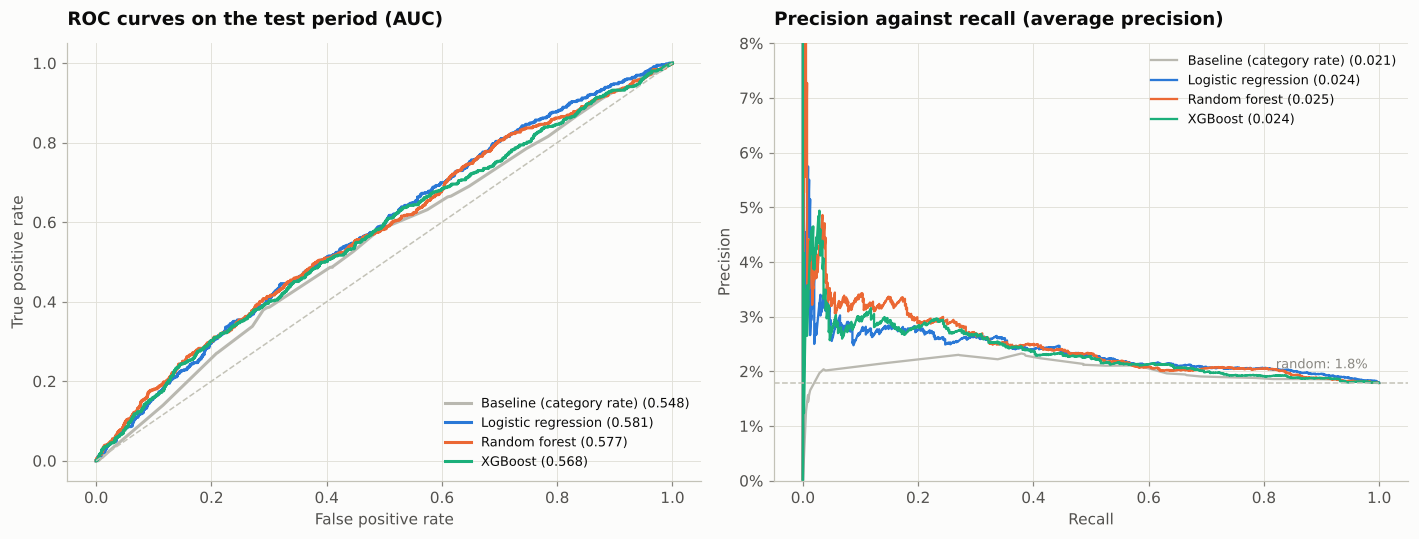

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, (name, p) in enumerate(scores.items()):
    color = ol.NEUTRAL if name.startswith("Baseline") else ol.SERIES[i - 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, linewidth=1.5, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=ol.AXIS, linestyle="--", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves on the test period (AUC)")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].axhline(y_test.mean(), color=ol.AXIS, linestyle="--", linewidth=1)
axes[1].text(0.98, y_test.mean() * 1.15, f"random: {y_test.mean():.1%}", ha="right", fontsize=8.5, color=ol.MUTED)
axes[1].set_ylim(0, 0.08)
ol.pct_axis(axes[1])
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision against recall (average precision)")
axes[1].legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
ol.save(fig, "04_roc_pr")
plt.show()

## 4. Choosing a model

The models are close, so the choice rests on two measures that fit how the scores would be used: average precision (how well the rare repeaters are ranked to the top) and lift in the top 10% (how much better a targeted campaign does than a random one).

Chosen model: Random forest


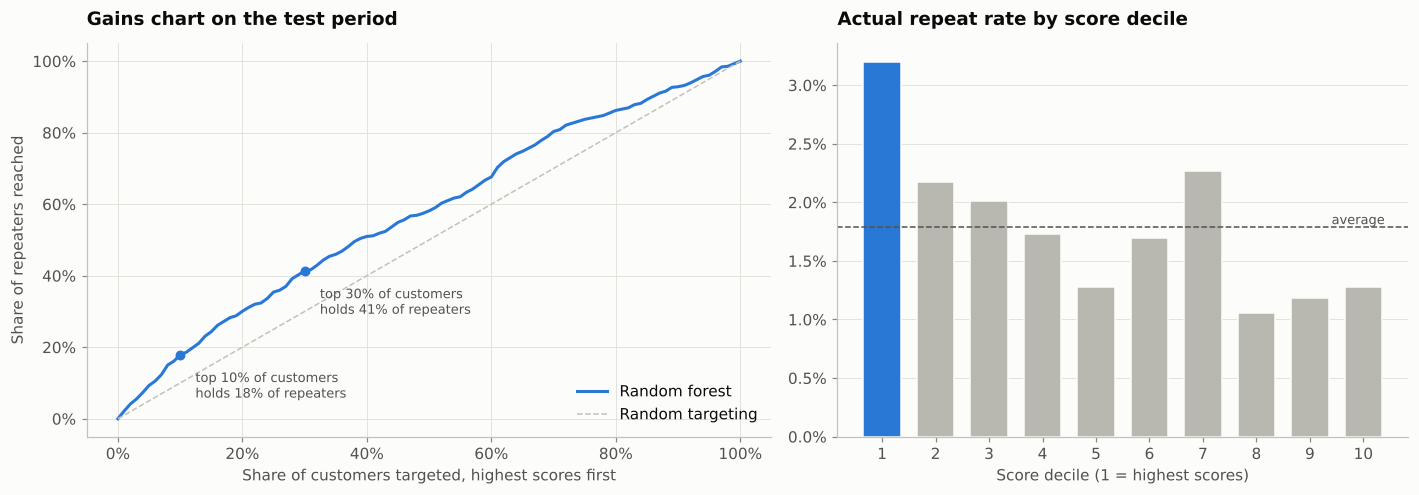

In [6]:
model_rows = results.drop(index="Baseline (category rate)")
best_name = (model_rows["PR AUC"].rank() + model_rows["lift top 10%"].rank()).idxmax()
best = models[best_name]
p_best = scores[best_name]
print(f"Chosen model: {best_name}")

share = np.linspace(0, 1, 101)
order = np.argsort(-p_best)
captured = np.concatenate([[0], np.cumsum(y_test.to_numpy()[order]) / y_test.sum()])
idx = (share * len(order)).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(share, captured[idx], color=ol.SERIES[0], label=best_name)
ax.plot([0, 1], [0, 1], color=ol.AXIS, linestyle="--", linewidth=1, label="Random targeting")
for s in (0.1, 0.3):
    v = captured[int(s * len(order))]
    ax.scatter([s], [v], color=ol.SERIES[0], s=30, zorder=3)
    ax.annotate(f"top {s:.0%} of customers\nholds {v:.0%} of repeaters", (s, v), textcoords="offset points",
                xytext=(10, -28), fontsize=8.5, color=ol.INK_2)
ol.pct_axis(ax)
ol.pct_axis(ax, axis="x")
ax.set_xlabel("Share of customers targeted, highest scores first")
ax.set_ylabel("Share of repeaters reached")
ax.set_title("Gains chart on the test period")
ax.legend(loc="lower right")

dec = pd.qcut(pd.Series(p_best).rank(method="first"), 10, labels=range(10, 0, -1))
dec_rate = pd.Series(y_test.to_numpy()).groupby(dec, observed=True).mean().sort_index()
axes[1].bar(dec_rate.index.astype(int), dec_rate.values,
            color=[ol.SERIES[0] if d == 1 else ol.NEUTRAL for d in dec_rate.index.astype(int)], width=0.7,
            edgecolor=ol.SURFACE)
axes[1].axhline(y_test.mean(), color=ol.INK_2, linestyle="--", linewidth=1)
axes[1].text(10.4, y_test.mean(), "average", va="bottom", ha="right", fontsize=8.5, color=ol.INK_2)
axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("Score decile (1 = highest scores)")
ol.pct_axis(axes[1], decimals=1)
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Actual repeat rate by score decile")
fig.tight_layout()
ol.save(fig, "04_gains_deciles")
plt.show()

In [7]:
top = p_best >= np.quantile(p_best, 0.9)
cm = confusion_matrix(y_test, top)
pd.DataFrame(cm, index=["did not return", "returned"], columns=["not targeted", "targeted (top 10%)"])

,not targeted,targeted (top 10%)
did not return,27684,3028
returned,459,100


## 5. What the model leans on

Permutation importance: shuffle one feature at a time on the test set and measure how much average precision drops. Unlike built-in tree importance, it is measured on unseen data and isn't biased towards features with many values. One-hot columns are shuffled as a group, so "category" is one feature, not 26.

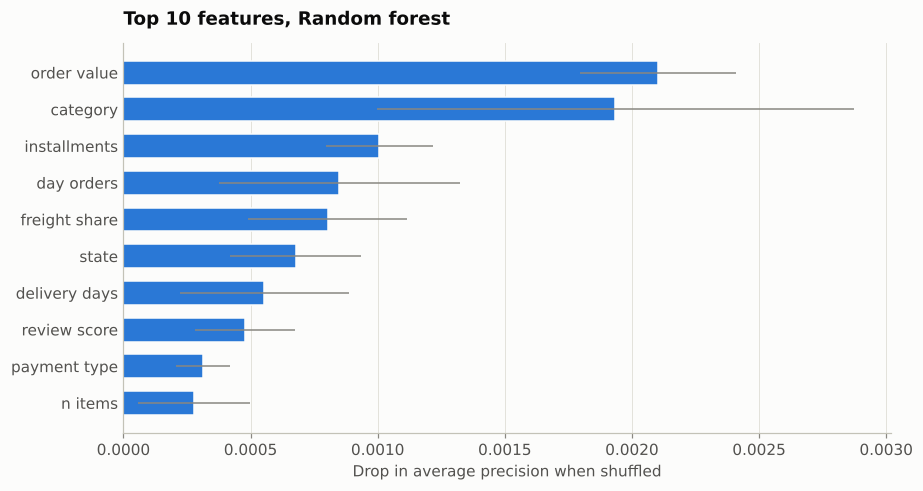

,drop,sd
order value,0.0021,0.0003
category,0.0019,0.0009
installments,0.0010,0.0002
day orders,0.0008,0.0005
freight share,0.0008,0.0003
state,0.0007,0.0003
delivery days,0.0006,0.0003
review score,0.0005,0.0002
payment type,0.0003,0.0001
n items,0.0003,0.0002


In [8]:
groups = {"category": [c for c in X_all.columns if c.startswith("cat_")],
          "state": [c for c in X_all.columns if c.startswith("state_")],
          "payment type": [c for c in X_all.columns if c.startswith("pay_")]}
for c in NUMERIC + ["review_missing", "not_delivered"]:
    groups[c.replace("first_", "").replace("_", " ")] = [c]

Xte_used = X_test if best_name == "XGBoost" else Xf_test
base_ap = average_precision_score(y_test, best.predict_proba(Xte_used)[:, 1])
rng = np.random.default_rng(0)
imp = {}
for name, cols in groups.items():
    drops = []
    for _ in range(5):
        Xs = Xte_used.copy()
        perm = rng.permutation(len(Xs))
        Xs[cols] = Xs[cols].to_numpy()[perm]
        drops.append(base_ap - average_precision_score(y_test, best.predict_proba(Xs)[:, 1]))
    imp[name] = (np.mean(drops), np.std(drops))
imp = pd.DataFrame(imp, index=["drop", "sd"]).T.sort_values("drop", ascending=False)
top_imp = imp.head(10)

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(top_imp))[::-1]
ax.barh(y, top_imp["drop"], xerr=top_imp["sd"], color=ol.SERIES[0], height=0.65, edgecolor=ol.SURFACE,
        error_kw={"ecolor": ol.MUTED, "lw": 1})
ax.set_yticks(y, top_imp.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in average precision when shuffled")
ax.set_title(f"Top 10 features, {best_name}")
ol.save(fig, "04_feature_importance")
plt.show()
imp.head(10)

In [9]:
lr = models["Logistic regression"]
coef = pd.Series(lr[-1].coef_[0], index=X_all.columns).sort_values()
print("Logistic regression, strongest standardised coefficients (positive = more likely to return):")
pd.concat([coef.head(6), coef.tail(6)]).to_frame("coefficient")

Logistic regression, strongest standardised coefficients (positive = more likely to return):


,coefficient
first_delay_days,-0.3313
first_promised_days,-0.2830
cat_cool_stuff,-0.1505
cat_housewares,-0.0954
state_CE,-0.0826
cat_telephony,-0.0738
cat_bed_bath_table,0.1034
first_freight_share,0.1046
first_day_orders,0.1234
cat_sports_leisure,0.1306


## 6. Calibration check, out of time

Class weighting pushes raw scores far above the real 2% rate. Isotonic calibration maps them back to honest probabilities. To check it works, the calibrated model is fitted on the training period only and its predictions compared with what actually happened in the test period.

In [10]:
cal_base = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=50, max_features="sqrt", n_jobs=-1,
                                            random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=2, min_child_weight=50,
                                 reg_lambda=10, subsample=0.8, colsample_bytree=0.7, random_state=42),
}
use_fill = best_name != "XGBoost"
cal_model = CalibratedClassifierCV(cal_base[best_name], method="isotonic", cv=5)
cal_model.fit(Xf_train if use_fill else X_train, y_train)
p_cal = cal_model.predict_proba(Xf_test if use_fill else X_test)[:, 1]

cal = pd.DataFrame({"p": p_cal, "y": y_test.to_numpy()})
cal["quintile"] = pd.qcut(cal["p"].rank(method="first"), 5, labels=["lowest", "2", "3", "4", "highest"])
cal_table = cal.groupby("quintile", observed=True).agg(predicted=("p", "mean"), actual=("y", "mean"),
                                                       customers=("y", "size"))
print(f"Test period: mean predicted {p_cal.mean():.2%}, actual {y_test.mean():.2%}")
cal_table

Test period: mean predicted 2.16%, actual 1.79%


,predicted,actual,customers
quintile,,,
lowest,0.0149,0.0115,6255
2,0.0183,0.0174,6254
3,0.0204,0.0160,6254
4,0.0221,0.0187,6254
highest,0.0322,0.0257,6254


## 7. Final model and scores

The chosen model is refitted on every labelled customer (train and test together) and wrapped in isotonic calibration, so its output reads as a real probability rather than a ranking score. Class weighting inflates raw scores; calibration brings them back to the 2% scale, which notebook 05 needs to value customers.

Every customer gets a score, including the 37,000 whose first purchase was too recent to label. Those recent customers are the ones a retention campaign can still reach.

Tiers: High = top 10% of scores, Medium = next 20%, Low = the rest.

In [11]:
X_lab = X_all[obs]
y_lab = y_all[obs].astype(int)
fill = X_lab.median()
final = CalibratedClassifierCV(cal_base[best_name], method="isotonic", cv=5)
final.fit(X_lab.fillna(fill) if use_fill else X_lab, y_lab)

X_score = X_all.fillna(fill) if use_fill else X_all
p_all = final.predict_proba(X_score)[:, 1]
cust["p_repeat_180d"] = p_all
rank = pd.Series(p_all).rank(pct=True, method="first")
cust["return_tier"] = np.select([rank > 0.9, rank > 0.7], ["High", "Medium"], "Low")

print(f"Mean predicted probability: {p_all.mean():.2%} (labelled customers' actual rate {y_lab.mean():.2%})")
print("Scores for labelled customers are in-sample, so their tiers flatter the model. "
      "Use the test-period figures above to judge it.")

Mean predicted probability: 2.07% (labelled customers' actual rate 1.98%)
Scores for labelled customers are in-sample, so their tiers flatter the model. Use the test-period figures above to judge it.


In [12]:
metrics = {"model": best_name, "test_customers": int(len(y_test)), "test_repeat_rate": float(y_test.mean()),
           "roc_auc": float(results.loc[best_name, "ROC AUC"]), "pr_auc": float(results.loc[best_name, "PR AUC"]),
           "top10_precision": float(results.loc[best_name, "precision top 10%"]),
           "top10_recall": float(results.loc[best_name, "recall top 10%"]),
           "top10_lift": float(results.loc[best_name, "lift top 10%"]),
           "baseline_roc_auc": float(results.loc["Baseline (category rate)", "ROC AUC"])}
with open(ol.PROCESSED / "model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

ol.MODELS.mkdir(parents=True, exist_ok=True)
with open(ol.MODELS / "repeat_model.pkl", "wb") as f:
    pickle.dump({"model": final, "features": list(X_all.columns), "fill": fill if use_fill else None,
                 "top_states": list(TOP_STATES), "top_categories": list(TOP_CATS), "name": best_name}, f)

out = cust[["customer_unique_id", "customer_state", "first_purchase", "first_lead_category", "total_spend",
            "repeat_180d_observed", "repeat_180d", "p_repeat_180d", "return_tier"]]
out.to_csv(ol.PROCESSED / "repeat_scores.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/repeat_scores.csv")
out.groupby("return_tier").agg(customers=("customer_unique_id", "size"), mean_p=("p_repeat_180d", "mean"),
                               not_yet_labelled=("repeat_180d_observed", lambda s: (s == 0).sum())).loc[
    ["High", "Medium", "Low"]]

Wrote 94,703 rows to data/processed/repeat_scores.csv


,customers,mean_p,not_yet_labelled
return_tier,,,
High,9471,0.0371,4750
Medium,18940,0.0243,9065
Low,66292,0.0173,23605


## Findings

1. The first order says little about whether a customer will return. The best models reach a ROC AUC of about 0.58 on the out-of-time test, where 0.5 is a coin toss. That is a real result, not a failed model: notebook 03 already showed no single feature moves the rate much, and combining them doesn't change that.
2. The models still beat the one-line category rule (AUC 0.55), and the random forest is the most useful for targeting. Its top 10% of scores returned at 3.2% against 1.8% on average, 1.8 times the rate, and held 18% of all repeaters.
3. Below the top decile the ranking is close to noise: deciles 2 to 10 bounce between about 1% and 2.3% with no clear order. The scores are good for one thing, picking a small group for a test campaign, and not for fine-grained decisions.
4. Category, order value and instalments carry most of what signal there is. Delivery and review features add little once those are in, which matches notebook 03: bad delivery hurts reviews far more than it hurts return rates.
5. After calibration the probabilities sit on the real 2% scale and keep their order, but on the test period they ran about a fifth high (2.16% predicted against 1.79% actual), because the Black Friday-heavy test customers returned less than the training ones. Notebook 05 uses them as approximate values, not exact ones.